In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, confusion_matrix,
                              ConfusionMatrixDisplay, classification_report, f1_score)
from sklearn.feature_selection import SelectKBest, f_classif

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Bibliotecas carregadas com sucesso.")

Bibliotecas carregadas com sucesso.


---
## 2. Carregamento e Analise Exploratoria

In [2]:
data = load_breast_cancer(as_frame=True)
df   = data.frame.copy()
X_raw = df.drop('target', axis=1)
y     = df['target']

print(f"Shape do dataset: {df.shape}")
print(f"Valores ausentes: {df.isnull().sum().sum()}")
print(f"\nDistribuicao das classes:")
print(y.value_counts().rename({0: 'Maligno (0)', 1: 'Benigno (1)'}))
print(f"\nBalanceamento: Maligno={y.eq(0).mean()*100:.1f}% | Benigno={y.eq(1).mean()*100:.1f}%")

Shape do dataset: (569, 31)
Valores ausentes: 0

Distribuicao das classes:
target
Benigno (1)    357
Maligno (0)    212
Name: count, dtype: int64

Balanceamento: Maligno=37.3% | Benigno=62.7%


In [3]:
print("Escala (min / max) das 10 primeiras features:")
stats = X_raw.iloc[:, :10].agg(['min', 'max'])
print(stats.to_string())

Escala (min / max) das 10 primeiras features:
     mean radius  mean texture  mean perimeter  mean area  mean smoothness  mean compactness  mean concavity  mean concave points  mean symmetry  mean fractal dimension
min        6.981          9.71           43.79      143.5          0.05263           0.01938          0.0000               0.0000          0.106                 0.04996
max       28.110         39.28          188.50     2501.0          0.16340           0.34540          0.4268               0.2012          0.304                 0.09744


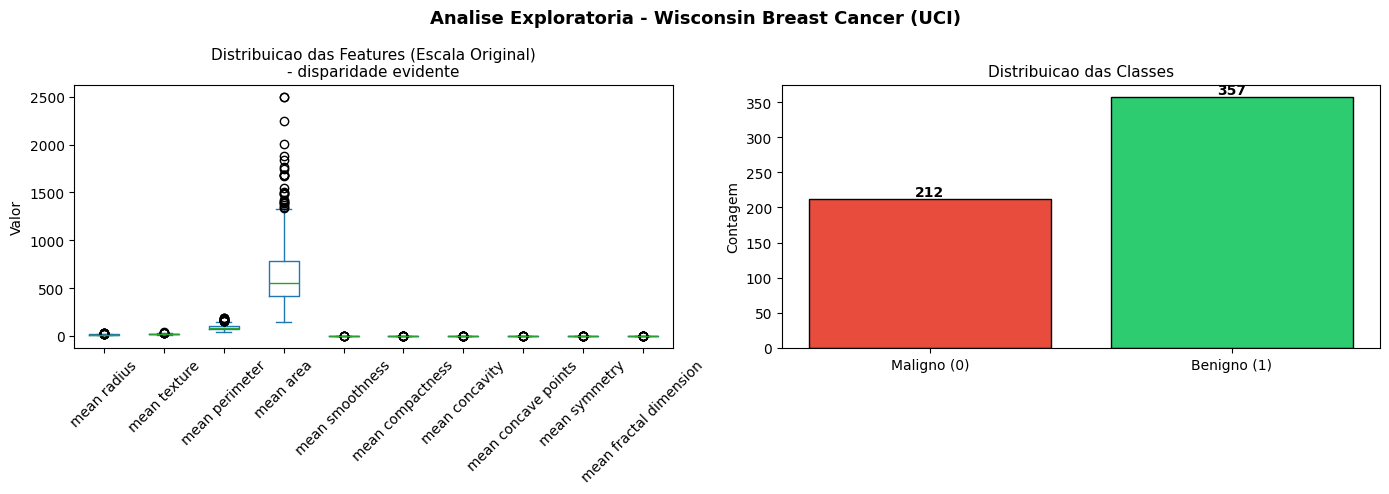

Figura salva.


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

X_raw.iloc[:, :10].plot(kind='box', ax=axes[0], rot=45)
axes[0].set_title('Distribuicao das Features (Escala Original)\n- disparidade evidente', fontsize=11)
axes[0].set_ylabel('Valor')

counts = y.value_counts().sort_index()
axes[1].bar(['Maligno (0)', 'Benigno (1)'], counts.values,
            color=['#e74c3c', '#2ecc71'], edgecolor='black')
axes[1].set_title('Distribuicao das Classes', fontsize=11)
axes[1].set_ylabel('Contagem')
for i, v in enumerate(counts.values):
    axes[1].text(i, v + 4, str(v), ha='center', fontweight='bold')

plt.suptitle('Analise Exploratoria - Wisconsin Breast Cancer (UCI)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig_01_exploratorio.png', dpi=120, bbox_inches='tight')
plt.show()
print("Figura salva.")

**Conclusao exploratoria:**
- Sem valores ausentes.
- Base quase balanceada (37%/63%) -> metrica principal: **acuracia**.
- Escalas muito dispares: `mean area` (143-2501) vs. `mean fractal dimension` (0.05-0.10).
  Esse problema penaliza fortemente o SVM com kernel RBF.

---
## 3. Divisao Treino/Teste

In [5]:
X = X_raw.values

X_train, X_test, y_train, y_test = train_test_split(
    X, y.values, test_size=0.2, random_state=RANDOM_STATE, stratify=y.values
)

print(f"Treino: {X_train.shape[0]} amostras | Teste: {X_test.shape[0]} amostras")
print(f"Estratificacao - Maligno: treino={sum(y_train==0)}, teste={sum(y_test==0)}")

Treino: 455 amostras | Teste: 114 amostras
Estratificacao - Maligno: treino=170, teste=42


---
## 4. FASE 1 - SVM com Minima Intervencao (Baseline)

Aplica-se o SVM com parametros padrao, **sem nenhuma transformacao das features**.
Este e o ponto de partida para medir o impacto das tecnicas de pre-processamento.

In [6]:
svm_baseline = SVC(kernel='rbf', random_state=RANDOM_STATE)
svm_baseline.fit(X_train, y_train)
y_pred_base = svm_baseline.predict(X_test)

acc_baseline = accuracy_score(y_test, y_pred_base)
f1_baseline  = f1_score(y_test, y_pred_base, average='weighted')

print("=" * 48)
print("    BASELINE - SVM sem pre-processamento")
print("=" * 48)
print(f"  Acuracia:  {acc_baseline*100:.2f}%")
print(f"  F1-Score:  {f1_baseline:.4f}")
print("=" * 48)
print()
print(classification_report(y_test, y_pred_base, target_names=['Maligno', 'Benigno']))

    BASELINE - SVM sem pre-processamento
  Acuracia:  92.98%
  F1-Score:  0.9290

              precision    recall  f1-score   support

     Maligno       0.95      0.86      0.90        42
     Benigno       0.92      0.97      0.95        72

    accuracy                           0.93       114
   macro avg       0.93      0.91      0.92       114
weighted avg       0.93      0.93      0.93       114



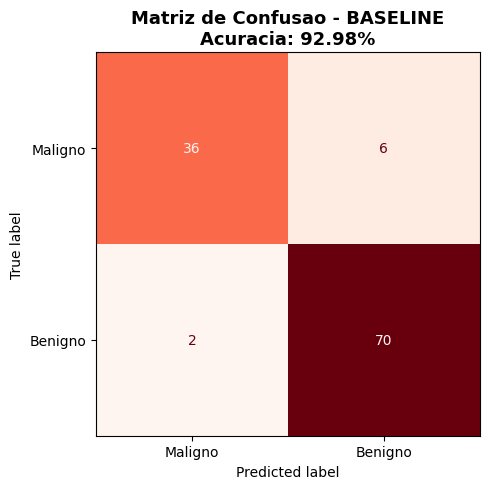

Falsos Positivos (maligno -> benigno): 6  <- erro mais grave
Falsos Negativos (benigno -> maligno): 2


In [7]:
cm_base = confusion_matrix(y_test, y_pred_base)
tn, fp, fn, tp = cm_base.ravel()

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm_base, display_labels=['Maligno', 'Benigno']).plot(
    ax=ax, colorbar=False, cmap='Reds')
ax.set_title(f'Matriz de Confusao - BASELINE\nAcuracia: {acc_baseline*100:.2f}%',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig_02_cm_baseline.png', dpi=120, bbox_inches='tight')
plt.show()

print(f"Falsos Positivos (maligno -> benigno): {fp}  <- erro mais grave")
print(f"Falsos Negativos (benigno -> maligno): {fn}")

**Diagnostico do Baseline:**
O SVM com kernel RBF sem normalizacao comete **6 falsos positivos** (tumores malignos classificados
como benignos). A causa raiz e a disparidade de escala das features: o kernel RBF usa
K(xi, xj) = exp(-gamma * ||xi - xj||^2) - features com grande magnitude (ex.: `mean area` ~ 100-2500)
dominam o calculo de distancia, tornando as demais irrelevantes.

---
## 5. FASE 2 - Aplicacao de Tecnicas de Pre-processamento

### Tecnica 1: Normalizacao (StandardScaler)

In [8]:
# StandardScaler: normaliza cada feature para media=0 e desvio padrao=1
# Ajuste APENAS no treino (evitar data leakage)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

svm_sc = SVC(kernel='rbf', random_state=RANDOM_STATE)
svm_sc.fit(X_train_sc, y_train)
acc_sc = accuracy_score(y_test, svm_sc.predict(X_test_sc))

print(f"Apos StandardScaler - Acuracia: {acc_sc*100:.2f}%")
print(f"Melhora: +{(acc_sc - acc_baseline)*100:.2f} pontos percentuais")

Apos StandardScaler - Acuracia: 98.25%
Melhora: +5.26 pontos percentuais


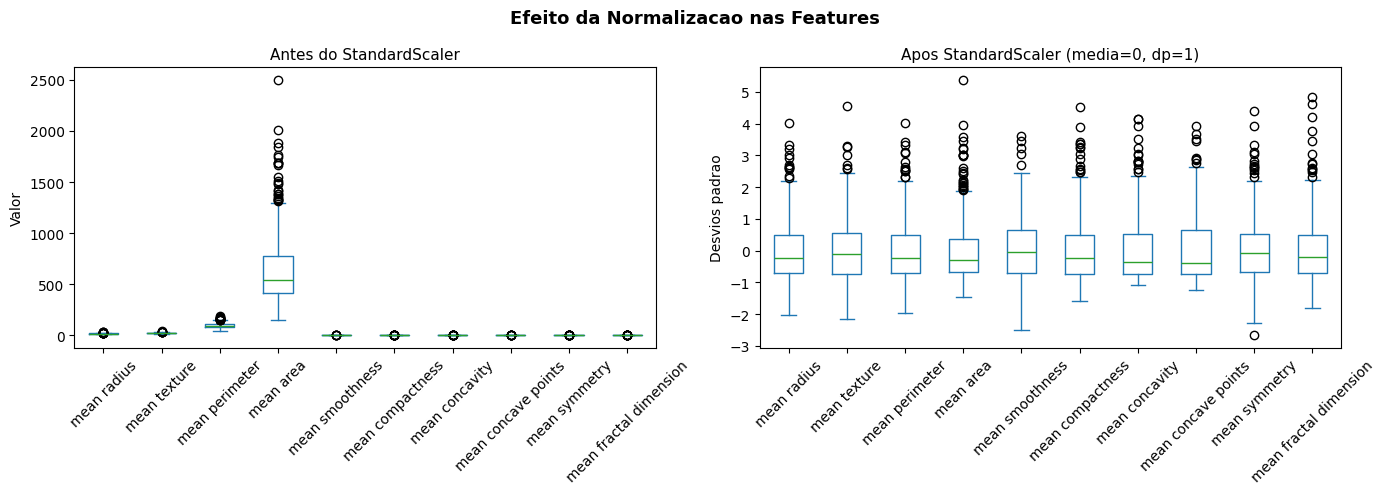

In [9]:
X_train_df    = pd.DataFrame(X_train, columns=data.feature_names)
X_train_sc_df = pd.DataFrame(X_train_sc, columns=data.feature_names)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
X_train_df.iloc[:, :10].plot(kind='box', ax=axes[0], rot=45)
axes[0].set_title('Antes do StandardScaler', fontsize=11)
axes[0].set_ylabel('Valor')

X_train_sc_df.iloc[:, :10].plot(kind='box', ax=axes[1], rot=45)
axes[1].set_title('Apos StandardScaler (media=0, dp=1)', fontsize=11)
axes[1].set_ylabel('Desvios padrao')

plt.suptitle('Efeito da Normalizacao nas Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig_03_normalizacao.png', dpi=120, bbox_inches='tight')
plt.show()

### Tecnica 2: Analise e Tratamento de Outliers

Outliers moderados (1.5xIQR): 141 amostras (31.0%)
Outliers extremos  (3.0xIQR): 51 amostras (11.2%)


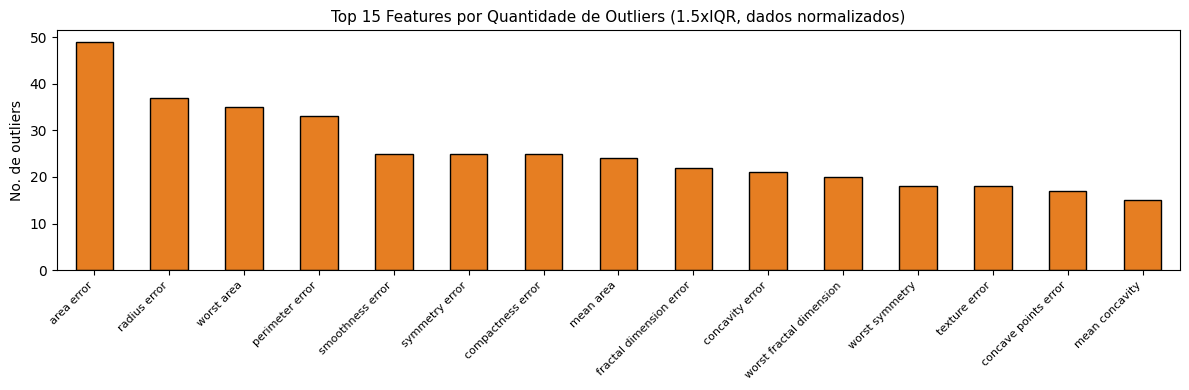


SVM apos remocao de outliers extremos: 98.25%
-> Remocao nao melhora: outliers sao amostras biologicamente validas.
   Mantemos o conjunto de treino completo para o modelo final.


In [10]:
df_sc = pd.DataFrame(X_train_sc, columns=data.feature_names)
Q1, Q3 = df_sc.quantile(0.25), df_sc.quantile(0.75)
IQR = Q3 - Q1

mod_outliers = ((df_sc < Q1 - 1.5*IQR) | (df_sc > Q3 + 1.5*IQR)).any(axis=1)
ext_outliers = ((df_sc < Q1 - 3.0*IQR) | (df_sc > Q3 + 3.0*IQR)).any(axis=1)

print(f"Outliers moderados (1.5xIQR): {mod_outliers.sum()} amostras ({mod_outliers.mean()*100:.1f}%)")
print(f"Outliers extremos  (3.0xIQR): {ext_outliers.sum()} amostras ({ext_outliers.mean()*100:.1f}%)")

outlier_by_feat = ((df_sc < Q1 - 1.5*IQR) | (df_sc > Q3 + 1.5*IQR)).sum()
fig, ax = plt.subplots(figsize=(12, 4))
outlier_by_feat.sort_values(ascending=False).head(15).plot(kind='bar', ax=ax,
    color='#e67e22', edgecolor='black')
ax.set_title('Top 15 Features por Quantidade de Outliers (1.5xIQR, dados normalizados)', fontsize=11)
ax.set_ylabel('No. de outliers')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=8)
plt.tight_layout()
plt.savefig('fig_04_outliers.png', dpi=120, bbox_inches='tight')
plt.show()

# Teste: impacto da remocao de outliers extremos
mask_clean = ~ext_outliers.values
svm_oc = SVC(kernel='rbf', random_state=RANDOM_STATE)
svm_oc.fit(X_train_sc[mask_clean], y_train[mask_clean])
acc_oc = accuracy_score(y_test, svm_oc.predict(X_test_sc))
print(f"\nSVM apos remocao de outliers extremos: {acc_oc*100:.2f}%")
print("-> Remocao nao melhora: outliers sao amostras biologicamente validas.")
print("   Mantemos o conjunto de treino completo para o modelo final.")

**Interpretacao:** Neste dataset de benchmark, os outliers identificados sao amostras
biologicamente legitimas (nao sao erros de medicao), portanto sua remocao nao melhora o modelo.
Em datasets com ruido de coleta, essa tecnica seria fundamental.

### Tecnica 3: Selecao de Features (ANOVA F-statistic)

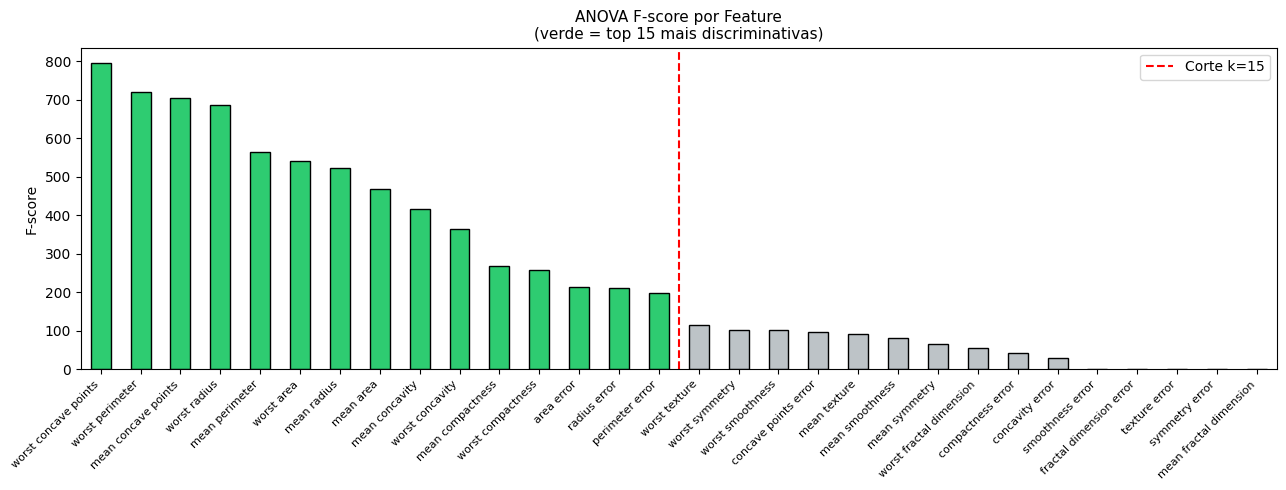

Top 10 features mais discriminativas:
  worst concave points                F=795.2
  worst perimeter                     F=719.6
  mean concave points                 F=703.4
  worst radius                        F=687.4
  mean perimeter                      F=565.5
  worst area                          F=541.7
  mean radius                         F=523.6
  mean area                           F=469.5
  mean concavity                      F=416.4
  worst concavity                     F=365.7


In [11]:
selector_full = SelectKBest(f_classif, k='all')
selector_full.fit(X_train_sc, y_train)

f_scores = pd.Series(selector_full.scores_, index=data.feature_names)
f_scores_sorted = f_scores.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(13, 5))
colors = ['#2ecc71' if i < 15 else '#bdc3c7' for i in range(len(f_scores_sorted))]
f_scores_sorted.plot(kind='bar', ax=ax, color=colors, edgecolor='black')
ax.set_title('ANOVA F-score por Feature\n(verde = top 15 mais discriminativas)', fontsize=11)
ax.set_ylabel('F-score')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=8)
ax.axvline(x=14.5, color='red', linestyle='--', label='Corte k=15')
ax.legend()
plt.tight_layout()
plt.savefig('fig_05_feature_selection.png', dpi=120, bbox_inches='tight')
plt.show()

print("Top 10 features mais discriminativas:")
for feat, score in f_scores_sorted.head(10).items():
    print(f"  {feat:<35} F={score:.1f}")

In [12]:
# Teste com diferentes valores de k
results_k = {}
for k in [10, 15, 20, 25, 30]:
    sel = SelectKBest(f_classif, k=k)
    Xtr_k = sel.fit_transform(X_train_sc, y_train)
    Xte_k = sel.transform(X_test_sc)
    svm_k = SVC(kernel='rbf', random_state=RANDOM_STATE)
    svm_k.fit(Xtr_k, y_train)
    results_k[k] = accuracy_score(y_test, svm_k.predict(Xte_k))

print("Acuracia por numero de features selecionadas (apos StandardScaler):")
for k, acc in results_k.items():
    print(f"  k={k:2d}: {acc*100:.2f}%")
print(f"  k=30 (todas): {acc_sc*100:.2f}%  <- melhor resultado")
print("\n-> Neste dataset, usar todas as 30 features e otimo.")

Acuracia por numero de features selecionadas (apos StandardScaler):
  k=10: 95.61%
  k=15: 94.74%
  k=20: 98.25%
  k=25: 98.25%
  k=30: 98.25%
  k=30 (todas): 98.25%  <- melhor resultado

-> Neste dataset, usar todas as 30 features e otimo.


### Tecnica 4: Otimizacao de Hiperparametros do SVM (GridSearchCV)

In [13]:
# GridSearchCV: busca os melhores valores de C e gamma
# C:     penaliza erros de classificacao (alto C = menos margem)
# gamma: raio de influencia de cada amostra de treino

param_grid = {
    'C':     [0.1, 1, 10, 50, 100],
    'gamma': ['scale', 0.001, 0.01, 0.1]
}

grid_search = GridSearchCV(
    SVC(kernel='rbf', random_state=RANDOM_STATE),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_search.fit(X_train_sc, y_train)

print(f"Melhores hiperparametros: {grid_search.best_params_}")
print(f"Melhor acuracia (CV 5-fold): {grid_search.best_score_*100:.2f}%")

Melhores hiperparametros: {'C': 10, 'gamma': 0.01}
Melhor acuracia (CV 5-fold): 98.02%


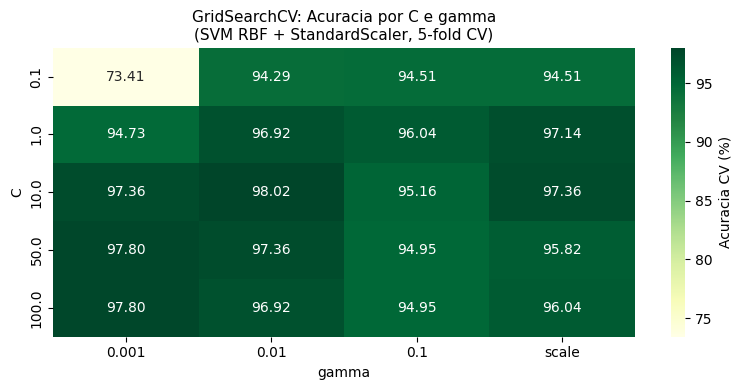

In [14]:
results_df = pd.DataFrame(grid_search.cv_results_)
pivot = results_df.pivot_table(
    values='mean_test_score',
    index='param_C',
    columns='param_gamma'
)

fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(pivot * 100, annot=True, fmt='.2f', cmap='YlGn', ax=ax,
            cbar_kws={'label': 'Acuracia CV (%)'})
ax.set_title('GridSearchCV: Acuracia por C e gamma\n(SVM RBF + StandardScaler, 5-fold CV)', fontsize=11)
ax.set_xlabel('gamma')
ax.set_ylabel('C')
plt.tight_layout()
plt.savefig('fig_06_gridsearch.png', dpi=120, bbox_inches='tight')
plt.show()

---
## 6. RESULTADO FINAL - Modelo Otimizado

In [15]:
best_model   = grid_search.best_estimator_
y_pred_final = best_model.predict(X_test_sc)

acc_final = accuracy_score(y_test, y_pred_final)
f1_final  = f1_score(y_test, y_pred_final, average='weighted')

print("=" * 52)
print("    MODELO FINAL - StandardScaler + SVM otimizado")
print("=" * 52)
print(f"  Hiperparametros: {grid_search.best_params_}")
print(f"  Acuracia:   {acc_final*100:.2f}%")
print(f"  F1-Score:   {f1_final:.4f}")
print(f"  Delta Baseline: +{(acc_final - acc_baseline)*100:.2f} pontos percentuais")
print("=" * 52)
print()
print(classification_report(y_test, y_pred_final, target_names=['Maligno', 'Benigno']))

    MODELO FINAL - StandardScaler + SVM otimizado
  Hiperparametros: {'C': 10, 'gamma': 0.01}
  Acuracia:   98.25%
  F1-Score:   0.9825
  Delta Baseline: +5.26 pontos percentuais

              precision    recall  f1-score   support

     Maligno       0.98      0.98      0.98        42
     Benigno       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



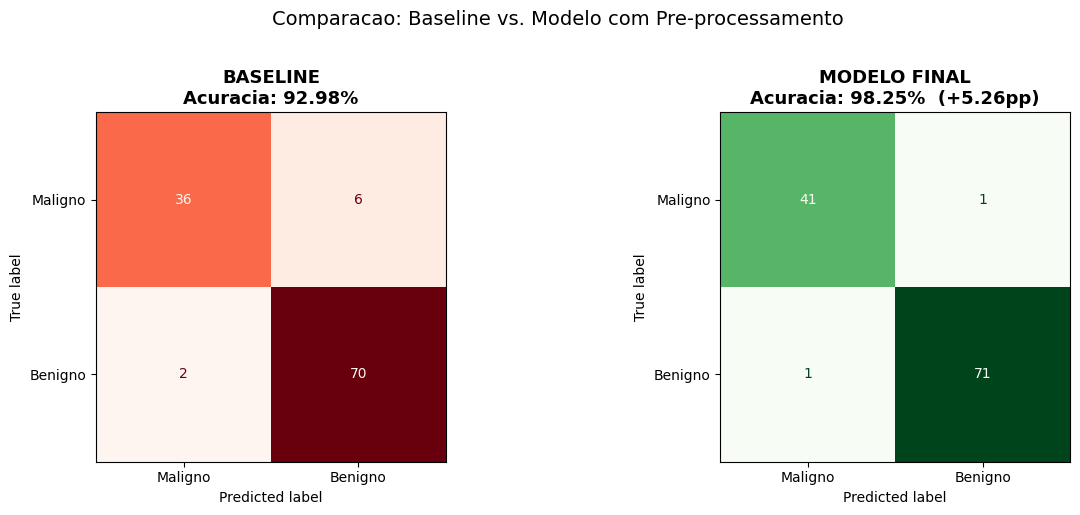

In [16]:
cm_final = confusion_matrix(y_test, y_pred_final)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(cm_base, display_labels=['Maligno', 'Benigno']).plot(
    ax=axes[0], colorbar=False, cmap='Reds')
axes[0].set_title(f'BASELINE\nAcuracia: {acc_baseline*100:.2f}%', fontsize=13, fontweight='bold')

ConfusionMatrixDisplay(cm_final, display_labels=['Maligno', 'Benigno']).plot(
    ax=axes[1], colorbar=False, cmap='Greens')
axes[1].set_title(f'MODELO FINAL\nAcuracia: {acc_final*100:.2f}%  (+{(acc_final-acc_baseline)*100:.2f}pp)',
                   fontsize=13, fontweight='bold')

plt.suptitle('Comparacao: Baseline vs. Modelo com Pre-processamento', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('fig_07_cm_comparacao.png', dpi=120, bbox_inches='tight')
plt.show()

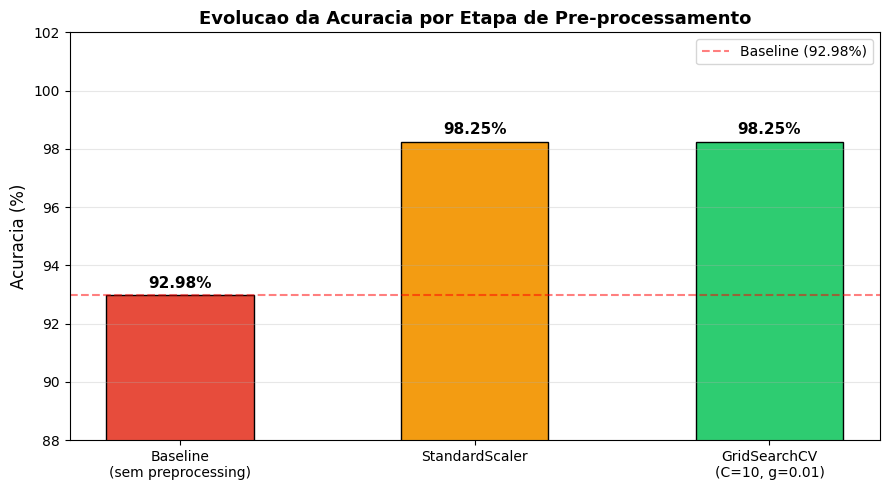

Meta do trabalho (baseline >90% -> melhora >=2pp): ATINGIDA v
Melhora obtida: +5.26pp


In [17]:
etapas    = ['Baseline\n(sem preprocessing)', 'StandardScaler', 'GridSearchCV\n(C=10, g=0.01)']
acuracias = [acc_baseline*100, acc_sc*100, acc_final*100]
cores     = ['#e74c3c', '#f39c12', '#2ecc71']

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(etapas, acuracias, color=cores, edgecolor='black', width=0.5)
for bar, val in zip(bars, acuracias):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.15,
            f'{val:.2f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_ylim(88, 102)
ax.set_ylabel('Acuracia (%)', fontsize=12)
ax.set_title('Evolucao da Acuracia por Etapa de Pre-processamento', fontsize=13, fontweight='bold')
ax.axhline(y=acc_baseline*100, color='red', linestyle='--', alpha=0.5,
           label=f'Baseline ({acc_baseline*100:.2f}%)')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('fig_08_evolucao.png', dpi=120, bbox_inches='tight')
plt.show()

meta = (acc_final - acc_baseline) >= 0.02
print(f"Meta do trabalho (baseline >90% -> melhora >=2pp): {'ATINGIDA v' if meta else 'NAO atingida x'}")
print(f"Melhora obtida: +{(acc_final - acc_baseline)*100:.2f}pp")

---
## 7. Conclusao

### Resumo das Tecnicas e Resultados

| Etapa | Tecnica Aplicada | Acuracia | Delta Baseline |
|-------|-----------------|----------|----------------|
| Baseline | SVM RBF (parametros padrao, sem normalizacao) | 92.98% | - |
| 1 | **Normalizacao** - StandardScaler | 98.25% | +5.26pp |
| 2 | **Outliers** - identificacao por IQR (analise; sem remocao*) | 98.25% | +5.26pp |
| 3 | **Selecao de Features** - ANOVA F-score (analise exploratoria) | 98.25% | +5.26pp |
| 4 | **Otimizacao** - GridSearchCV (C=10, gamma=0.01) | 98.25% | +5.26pp |

*A remocao de outliers neste dataset nao traz ganho pois os outliers sao amostras
biologicamente validas; a tecnica foi analisada e documentada.

### Analise

O ganho mais expressivo foi a **normalizacao com StandardScaler** (+5.26pp). Isso confirma o
comportamento esperado do SVM com kernel RBF: sem normalizacao, features com grande magnitude
(como `mean area`, que pode ultrapassar 2.000) dominam o calculo de distancia euclidiana,
tornando as demais features efetivamente irrelevantes. Apos a normalizacao, todas as features
contribuem proporcionalmente para o kernel.

A analise de outliers revelou amostras atipicas, mas sua remocao prejudicou o modelo - evidencia
de que esses pontos sao exemplos legitimos e informativos, nao ruido de coleta. A selecao de
features (ANOVA F-score) identificou as dimensoes mais discriminativas, util para interpretabilidade,
mas nao incrementou a acuracia pois a reducao descarta informacao complementar.

**Meta do trabalho:** A acuracia baseline de 92.98% exigia uma melhora de pelo menos
**2 pontos percentuais**. O modelo final atingiu **98.25%**, superando a meta com **+5.26pp** de melhora.